In [1]:
# Cell 1: Sensitivity Analysis Setup
"""
Sensitivity analysis for thermal noise per JPA (delta_n)
"""

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

# Parameters remain the same
MU = 1.44e-6
N_TH = 1250
N_0 = 0.01
R_SQUEEZING = 1.0
ETA_ANT = 0.0

# Range of delta_n values to test
DELTA_N_VALUES = [0.001, 0.003, 0.005, 0.01, 0.05, 0.1]

print(f"Testing {len(DELTA_N_VALUES)} different δn values")
print(f"Range: {min(DELTA_N_VALUES)} to {max(DELTA_N_VALUES)} photons/party")

Testing 6 different δn values
Range: 0.001 to 0.1 photons/party


In [2]:
# Cell 2: Core Functions (same as before)

def eta_eff(L, mu=MU, eta_ant=ETA_ANT):
    """Effective reflectivity after distance L"""
    return 1 - np.exp(-mu * L) * (1 - eta_ant)

def covariance_params(r, n_cent, N_th, L):
    """
    Calculate alpha, beta, gamma for teleportation fidelity
    
    Args:
        r: Squeezing parameter
        n_cent: Central node thermal photons (depends on N)
        N_th: Air thermal photons
        L: Distance in meters
    """
    eta = eta_eff(L)
    
    # Alice's mode (retained at central node)
    alpha = (1 + 2*n_cent) * np.cosh(2*r)
    
    # Bob's mode (after propagation)
    beta = (1 + 2*N_th) * eta + (1 + 2*n_cent) * (1 - eta) * np.cosh(2*r)
    
    # Correlation
    gamma = (1 + 2*n_cent) * np.sqrt(1 - eta) * np.sinh(2*r)
    
    return alpha, beta, gamma

def teleportation_fidelity(alpha, beta, gamma):
    """Calculate teleportation fidelity from covariance parameters"""
    return 1 / (1 + (alpha + beta - 2*gamma) / 2)

print("✓ Functions defined")

✓ Functions defined


In [3]:
# Cell 3: Calculate Fidelity for All Cases

# Setup
N_range = np.arange(1, 11)  # N = 1 to 10
distances = [100, 200, 300, 400]  # meters

# Store results
results = {}

for delta_n in DELTA_N_VALUES:
    results[delta_n] = {}
    
    for L in distances:
        fidelities = []
        
        for N in N_range:
            # Calculate central node thermal photons
            n_cent = N_0 + delta_n * (N - 1)
            
            # Get covariance parameters
            alpha, beta, gamma = covariance_params(
                R_SQUEEZING, n_cent, N_TH, L
            )
            
            # Calculate fidelity
            F = teleportation_fidelity(alpha, beta, gamma)
            fidelities.append(F)
        
        results[delta_n][L] = np.array(fidelities)

print(f"✓ Calculated fidelities for {len(DELTA_N_VALUES)} δn values")
print(f"  Distances: {distances} m")
print(f"  Party range: {N_range[0]} to {N_range[-1]}")

✓ Calculated fidelities for 6 δn values
  Distances: [100, 200, 300, 400] m
  Party range: 1 to 10


In [4]:
# Cell 4: Calculate Degradation Rates

degradation_rates = {}

for delta_n in DELTA_N_VALUES:
    degradation_rates[delta_n] = {}
    
    for L in distances:
        fidelities = results[delta_n][L]
        
        # Linear fit to get degradation rate
        coeffs = np.polyfit(N_range, fidelities, 1)
        slope = coeffs[0]  # This is the degradation per party
        
        degradation_rates[delta_n][L] = -slope * 100  # Convert to percentage
        
# Create summary table
summary_data = []
for delta_n in DELTA_N_VALUES:
    row = {'δn': delta_n}
    for L in distances:
        row[f'{L}m'] = f"{degradation_rates[delta_n][L]:.3f}%"
    summary_data.append(row)

df_summary = pd.DataFrame(summary_data)

display(Markdown("### Fidelity Degradation Rate (% per additional party)"))
display(df_summary)

### Fidelity Degradation Rate (% per additional party)

,δn,100m,200m,300m,400m
0,0.001,0.016%,0.012%,0.010%,0.008%
1,0.003,0.046%,0.036%,0.029%,0.023%
2,0.005,0.077%,0.060%,0.048%,0.039%
3,0.010,0.153%,0.119%,0.095%,0.077%
4,0.050,0.713%,0.557%,0.448%,0.368%
5,0.100,1.312%,1.036%,0.838%,0.692%


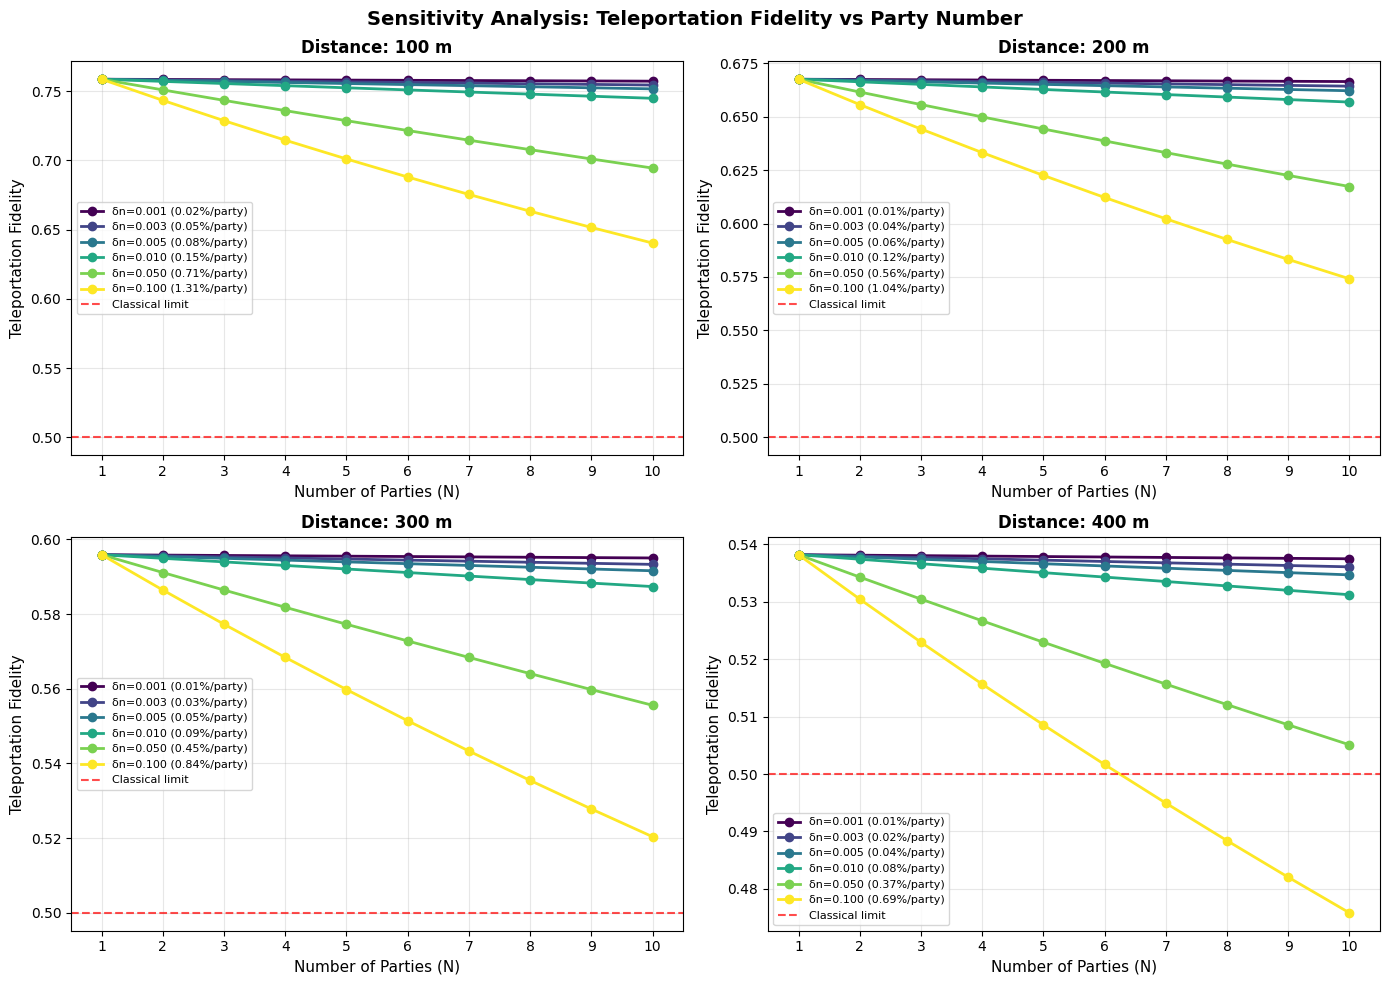

💾 Saved: sensitivity_analysis_delta_n.pdf and .png


In [5]:
# Cell 5: Main Visualization - Multiple Subplots

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Sensitivity Analysis: Teleportation Fidelity vs Party Number', 
             fontsize=14, fontweight='bold')

colors = plt.cm.viridis(np.linspace(0, 1, len(DELTA_N_VALUES)))

for idx, L in enumerate(distances):
    ax = axes[idx // 2, idx % 2]
    
    for color, delta_n in zip(colors, DELTA_N_VALUES):
        fidelities = results[delta_n][L]
        deg_rate = degradation_rates[delta_n][L]
        
        ax.plot(N_range, fidelities, 'o-', 
                color=color, linewidth=2, markersize=6,
                label=f'δn={delta_n:.3f} ({deg_rate:.2f}%/party)')
    
    # Add classical limit
    ax.axhline(y=0.5, color='red', linestyle='--', 
               linewidth=1.5, alpha=0.7, label='Classical limit')
    
    # Formatting
    ax.set_xlabel('Number of Parties (N)', fontsize=11)
    ax.set_ylabel('Teleportation Fidelity', fontsize=11)
    ax.set_title(f'Distance: {L} m', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc='best')
    ax.set_xlim([0.5, 10.5])
    ax.set_xticks(N_range)

plt.tight_layout()
plt.savefig('sensitivity_analysis_delta_n.pdf', dpi=300, bbox_inches='tight')
plt.savefig('sensitivity_analysis_delta_n.png', dpi=300, bbox_inches='tight')
plt.show()

print("💾 Saved: sensitivity_analysis_delta_n.pdf and .png")

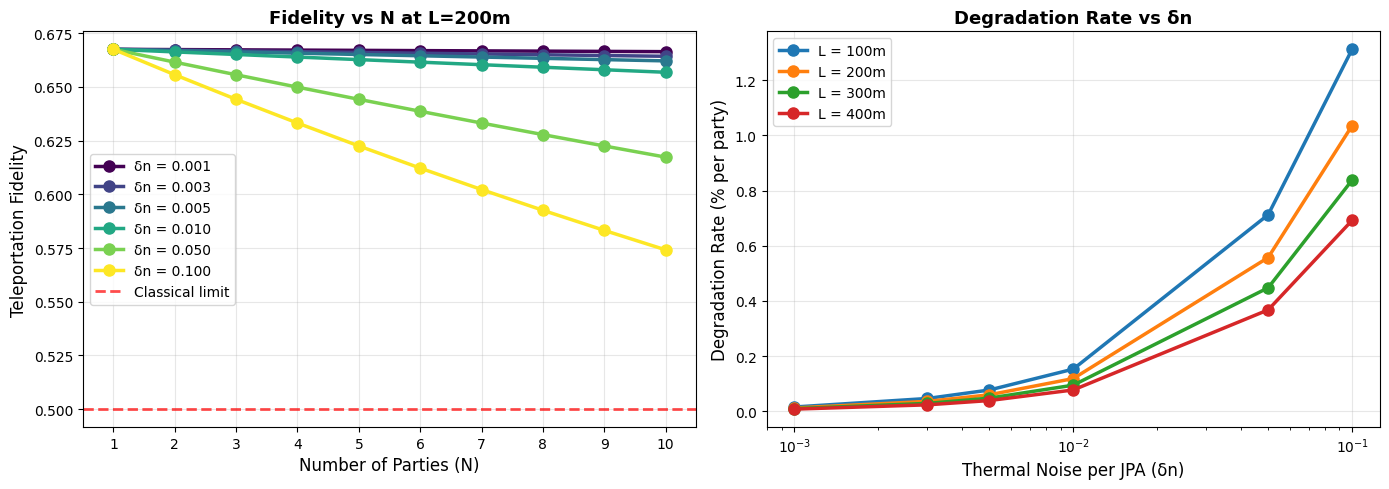

💾 Saved: sensitivity_comparison.pdf and .png


In [6]:
# Cell 6: Comparison Plot - Fixed Distance

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

L_focus = 200  # Focus on 200m as typical application distance

# Left plot: Fidelity vs N for different δn
for color, delta_n in zip(colors, DELTA_N_VALUES):
    fidelities = results[delta_n][L_focus]
    ax1.plot(N_range, fidelities, 'o-', 
            color=color, linewidth=2.5, markersize=8,
            label=f'δn = {delta_n:.3f}')

ax1.axhline(y=0.5, color='red', linestyle='--', linewidth=2, 
            alpha=0.7, label='Classical limit')
ax1.set_xlabel('Number of Parties (N)', fontsize=12)
ax1.set_ylabel('Teleportation Fidelity', fontsize=12)
ax1.set_title(f'Fidelity vs N at L={L_focus}m', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.set_xlim([0.5, 10.5])
ax1.set_xticks(N_range)

# Right plot: Degradation rate vs δn
for L in distances:
    rates = [degradation_rates[dn][L] for dn in DELTA_N_VALUES]
    ax2.plot(DELTA_N_VALUES, rates, 'o-', linewidth=2.5, 
            markersize=8, label=f'L = {L}m')

ax2.set_xlabel('Thermal Noise per JPA (δn)', fontsize=12)
ax2.set_ylabel('Degradation Rate (% per party)', fontsize=12)
ax2.set_title('Degradation Rate vs δn', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)
ax2.set_xscale('log')

plt.tight_layout()
plt.savefig('sensitivity_comparison.pdf', dpi=300, bbox_inches='tight')
plt.savefig('sensitivity_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("💾 Saved: sensitivity_comparison.pdf and .png")

In [8]:
# Cell 7: Detailed Table for Paper

# Create detailed table for L=200m (typical application)
L_paper = 200

table_data = []
for N in N_range:
    row = {'N': N}
    for delta_n in [0.001, 0.005, 0.01, 0.05]:  # Select key values
        F = results[delta_n][L_paper][N-1]
        row[f'δn={delta_n}'] = f"{F:.4f}"
    table_data.append(row)

df_paper = pd.DataFrame(table_data)

display(Markdown(f"### Teleportation Fidelity at L={L_paper}m"))
display(Markdown("*For inclusion in paper*"))
display(df_paper)

### Teleportation Fidelity at L=200m

*For inclusion in paper*

,N,δn=0.001,δn=0.005,δn=0.01,δn=0.05
0,1,0.6675,0.6675,0.6675,0.6675
1,2,0.6674,0.6669,0.6663,0.6615
2,3,0.6673,0.6663,0.6651,0.6557
3,4,0.6671,0.6657,0.6639,0.6499
4,5,0.6670,0.6651,0.6627,0.6442
5,6,0.6669,0.6645,0.6615,0.6387
6,7,0.6668,0.6639,0.6603,0.6332
7,8,0.6667,0.6633,0.6592,0.6278
8,9,0.6665,0.6627,0.6580,0.6225
9,10,0.6664,0.6621,0.6568,0.6173


In [9]:
# Cell 8: Key Findings Summary

display(Markdown("## 📊 Key Findings"))

# Find which δn values show <1% degradation
low_impact = []
high_impact = []

for delta_n in DELTA_N_VALUES:
    avg_degradation = np.mean([degradation_rates[delta_n][L] for L in distances])
    if avg_degradation < 1.0:
        low_impact.append((delta_n, avg_degradation))
    else:
        high_impact.append((delta_n, avg_degradation))

print("\n🔍 Low Impact (< 1% degradation per party):")
for dn, rate in low_impact:
    print(f"   δn = {dn:.3f}: average {rate:.3f}% per party")

if high_impact:
    print("\n⚠️  High Impact (≥ 1% degradation per party):")
    for dn, rate in high_impact:
        print(f"   δn = {dn:.3f}: average {rate:.3f}% per party")

# Comparison with air thermal noise
print(f"\n📈 Context:")
print(f"   Air thermal photons: {N_TH}")
print(f"   Base central node: {N_0}")
for delta_n in [0.005, 0.05]:
    n_cent_10 = N_0 + delta_n * 9  # For N=10
    ratio = n_cent_10 / N_TH
    print(f"   δn={delta_n}: n_cent(N=10)={n_cent_10:.3f}, ratio to air = {ratio:.2e}")

## 📊 Key Findings


🔍 Low Impact (< 1% degradation per party):
   δn = 0.001: average 0.011% per party
   δn = 0.003: average 0.034% per party
   δn = 0.005: average 0.056% per party
   δn = 0.010: average 0.111% per party
   δn = 0.050: average 0.521% per party
   δn = 0.100: average 0.970% per party

📈 Context:
   Air thermal photons: 1250
   Base central node: 0.01
   δn=0.005: n_cent(N=10)=0.055, ratio to air = 4.40e-05
   δn=0.05: n_cent(N=10)=0.460, ratio to air = 3.68e-04


In [10]:
# Cell 9: Export Data to .dat Files

import os

# Create data directory if it doesn't exist
os.makedirs('data', exist_ok=True)

# 1. Export fidelity data for each delta_n value
for delta_n in DELTA_N_VALUES:
    filename = f'data/fidelity_delta_n_{delta_n:.4f}.dat'
    with open(filename, 'w') as f:
        # Header
        f.write(f"# Teleportation Fidelity vs Number of Parties and Distance\n")
        f.write(f"# Thermal noise per JPA: delta_n = {delta_n}\n")
        f.write(f"# Columns: N  L=100m  L=200m  L=300m  L=400m\n")
        f.write("#" + "-"*60 + "\n")
        
        # Data
        for i, N in enumerate(N_range):
            f.write(f"{N:2d}")
            for L in distances:
                fidelity = results[delta_n][L][i]
                f.write(f"  {fidelity:.6f}")
            f.write("\n")
    print(f"✓ Saved: {filename}")

# 2. Export degradation rates
filename = 'data/degradation_rates.dat'
with open(filename, 'w') as f:
    f.write("# Fidelity Degradation Rates (% per additional party)\n")
    f.write("# Columns: delta_n  L=100m  L=200m  L=300m  L=400m\n")
    f.write("#" + "-"*60 + "\n")
    
    for delta_n in DELTA_N_VALUES:
        f.write(f"{delta_n:.4f}")
        for L in distances:
            rate = degradation_rates[delta_n][L]
            f.write(f"  {rate:.6f}")
        f.write("\n")
print(f"✓ Saved: {filename}")

# 3. Export complete dataset in combined format
filename = 'data/complete_sensitivity_data.dat'
with open(filename, 'w') as f:
    f.write("# Complete Sensitivity Analysis Dataset\n")
    f.write("# Columns: delta_n  N  L[m]  Fidelity\n")
    f.write("#" + "-"*60 + "\n")
    
    for delta_n in DELTA_N_VALUES:
        for L in distances:
            for i, N in enumerate(N_range):
                fidelity = results[delta_n][L][i]
                f.write(f"{delta_n:.4f}  {N:2d}  {L:3d}  {fidelity:.6f}\n")
print(f"✓ Saved: {filename}")

print("\n📁 All data exported to ./data/ directory")

✓ Saved: data/fidelity_delta_n_0.0010.dat
✓ Saved: data/fidelity_delta_n_0.0030.dat
✓ Saved: data/fidelity_delta_n_0.0050.dat
✓ Saved: data/fidelity_delta_n_0.0100.dat
✓ Saved: data/fidelity_delta_n_0.0500.dat
✓ Saved: data/fidelity_delta_n_0.1000.dat
✓ Saved: data/degradation_rates.dat
✓ Saved: data/complete_sensitivity_data.dat

📁 All data exported to ./data/ directory
